In [1]:
import re
from collections import Counter

import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS

import matplotlib.pyplot as plt
plt.style.use("Solarize_Light2")

In [2]:
import ast
from sklearn.preprocessing import MultiLabelBinarizer

def parse_labels(cell):
    if not isinstance(cell, str) or not cell.strip():
        return []
    return [x.strip() for x in ast.literal_eval(cell)]

df = pd.read_csv("fourth_round_llm.csv", dtype=str, keep_default_na=False)
df["llm_labels"] = df["llm_labels"].apply(parse_labels)
df["labels"] = df["labels"].apply(parse_labels)      # hand labels are stored the same way

mlb = MultiLabelBinarizer()
y = pd.DataFrame(mlb.fit_transform(df["llm_labels"]), columns=mlb.classes_, index=df.index)
df = df.join(y)

In [3]:
df["labels"] = df["labels"].apply(lambda xs: ["ableism" if x == "abelism" else x for x in xs]) # fixing typo in the labels column

In [4]:
df["labels"] = df["labels"].apply(lambda xs: ["age-appropriateness" if x == "age" else x for x in xs]) # changing "age" to "age-appropriateness" for a clearer label in the labels column

In [5]:
# filtering the dataframe to only include reviews that have been flagged as inappropriate, and selecting the relevant columns for further analysis
df_analysis = df[["review_id", "llm_labels"]]

df_analysis.head(5)

,review_id,llm_labels
0,8271a9e037ebe67dab6376fe498dbcf9,"[religion, age-appropriateness, bad-influence]"
1,acf5e394790f363eec00bb12df9d806a,"[age-appropriateness, bad-influence, abuse]"
2,dafeeb582114e849cb971e71f97f660a,"[religion, age-appropriateness]"
3,206b8919325f9737f91286d6c9e3e0a9,"[age-appropriateness, illustrations, crude-lan..."
4,e0337f5711a585a85a238d53f122ed69,"[racism, classism, age-appropriateness]"


In [6]:
len(df_analysis)

163

In [7]:
df_analysis["llm_labels"].explode().value_counts()

llm_labels
age-appropriateness    113
scary/dark              46
bad-influence           32
racism                  27
crude-language          23
illustrations           19
violence                19
drugs/alcohol           13
religion                11
sexism                   9
abuse                    5
classism                 5
non-factual              5
body-shaming             4
ableism                  4
preachy                  4
witchcraft               2
sexuality                1
Name: count, dtype: int64

In [8]:
# reviews explicitly flagged for age-appropriateness versus not flagged for age-appropriateness
exploded = df_analysis["llm_labels"].explode()
age_ids = exploded[exploded == "age-appropriateness"].index.unique()

df_analysis = df_analysis.copy()
df_analysis["has_age"] = df_analysis.index.isin(age_ids)

df_age_only = df_analysis[df_analysis["has_age"]]
df_not_age = df_analysis[~df_analysis["has_age"]]

print(df_analysis["has_age"].value_counts())

pct_of_age = round(df_analysis["has_age"].sum() / len(df_analysis) * 100, 1) # calculating the percentage of reviews that have been flagged for age-appropriateness

num_age = df_analysis["has_age"].sum()
num_total = len(df_analysis)
print(f"{num_age} of {num_total} reviews ({num_age / num_total * 100:.1f}%) are labeled age-appropriateness")

has_age
True     113
False     50
Name: count, dtype: int64
113 of 163 reviews (69.3%) are labeled age-appropriateness


In [9]:
counts = df_analysis["llm_labels"].explode().value_counts().head(10)
pct_of_reviews = (counts / len(df_analysis) * 100).round(1) # calculating the percentage of reviews that have been flagged for each label
print(pct_of_reviews)

llm_labels
age-appropriateness    69.3
scary/dark             28.2
bad-influence          19.6
racism                 16.6
crude-language         14.1
illustrations          11.7
violence               11.7
drugs/alcohol           8.0
religion                6.7
sexism                  5.5
Name: count, dtype: float64


In [10]:
# looking at the number of reviews for every label and the percentage of those reviews that have also been flagged as age-appropriateness, to see which labels are most often associated with age-appropriateness

label_column = df_analysis[["llm_labels"]].copy() # copy of dataframe with only the llm labels column. double-brackets are used to keep it as a dataframe instead of a series, so that we can use the explode method on it
label_column["has_age"] = label_column["llm_labels"].apply(lambda xs: "age-appropriateness" in xs) # checking if the list of labels for each review contains "age-appropriateness" and creating a new column called "has_age" that contains a boolean value indicating whether or not the review has been flagged as age-appropriateness
label_column = label_column.explode("llm_labels").dropna(subset=["llm_labels"]) # turning the list of labels for each review into separate rows, so that each row corresponds to a single label for a single review, and dropping any rows with missing values in the labels column
label_column = label_column[label_column["llm_labels"] != "age-appropriateness"] # filtering out the age-appropriateness label from the dataframe, so that we can see how many reviews have been flagged for other labels in addition to age-appropriateness

result = (label_column.groupby("llm_labels")["has_age"] # grouping the dataframe by label and counting how many reviews have been flagged as age-appropriateness for each label, and how many reviews have been flagged for each label in total
             .agg(n_reviews="size", also_age_appropriate="sum"))

result["pct"] = (result["also_age_appropriate"] / result["n_reviews"] * 100).round(1) # calculating the percentage of reviews that have been flagged as age-appropriateness for each label
result = result.sort_values("pct", ascending=False) # sorting results by descending percentage of reviews
print(result)

                n_reviews  also_age_appropriate    pct
llm_labels                                            
bad-influence          32                    32  100.0
body-shaming            4                     4  100.0
drugs/alcohol          13                    13  100.0
sexuality               1                     1  100.0
crude-language         23                    22   95.7
violence               19                    17   89.5
scary/dark             46                    36   78.3
sexism                  9                     7   77.8
illustrations          19                    13   68.4
classism                5                     3   60.0
abuse                   5                     3   60.0
religion               11                     6   54.5
witchcraft              2                     1   50.0
preachy                 4                     2   50.0
racism                 27                     7   25.9
ableism                 4                     1   25.0
non-factua

The following labels had 100% of their reviews also labeled with "age-appropriateness": 
"bad-influence", "body-shaming", "drugs/alcohol", "sexuality"

In [11]:
# filtering the dataframe to only include reviews that have been flagged as age-appropriateness, and creating a copy of the filtered dataframe to avoid modifying the original dataframe
df_age = df_analysis[df_analysis["llm_labels"].apply(lambda xs: "age-appropriateness" in xs)].copy() 

n = len(df_age)
n # total number of reviews that have been flagged as age-appropriateness

113

In [12]:
df_age.head(1)

,review_id,llm_labels,has_age
0,8271a9e037ebe67dab6376fe498dbcf9,"[religion, age-appropriateness, bad-influence]",True


In [13]:
others = (df_age["llm_labels"].explode() # counting how many reviews have been flagged for each label
          .loc[lambda s: s != "age-appropriateness"] # filtering out the "age-appropriateness" label from the counts, so that we can see how many reviews have been flagged for other labels in addition to age-appropriateness
          .value_counts())
print(others)

llm_labels
scary/dark        36
bad-influence     32
crude-language    22
violence          17
illustrations     13
drugs/alcohol     13
racism             7
sexism             7
religion           6
body-shaming       4
abuse              3
classism           3
preachy            2
sexuality          1
witchcraft         1
ableism            1
non-factual        1
Name: count, dtype: int64


In [14]:
pct_others_and_age = (others / n * 100).round(1) # calculating the percentage of age-appropriateness labeled reviews that have been flagged with another label
print(pct_others_and_age)

llm_labels
scary/dark        31.9
bad-influence     28.3
crude-language    19.5
violence          15.0
illustrations     11.5
drugs/alcohol     11.5
racism             6.2
sexism             6.2
religion           5.3
body-shaming       3.5
abuse              2.7
classism           2.7
preachy            1.8
sexuality          0.9
witchcraft         0.9
ableism            0.9
non-factual        0.9
Name: count, dtype: float64


# Visualizations

### Visualizing top ten themes for reviews marked as inappropriate complaint. 

#### Themes shown as a percentage of total reviews. Because some reviews may be flagged with multiple labels, the percentage totals don't equal 100. 

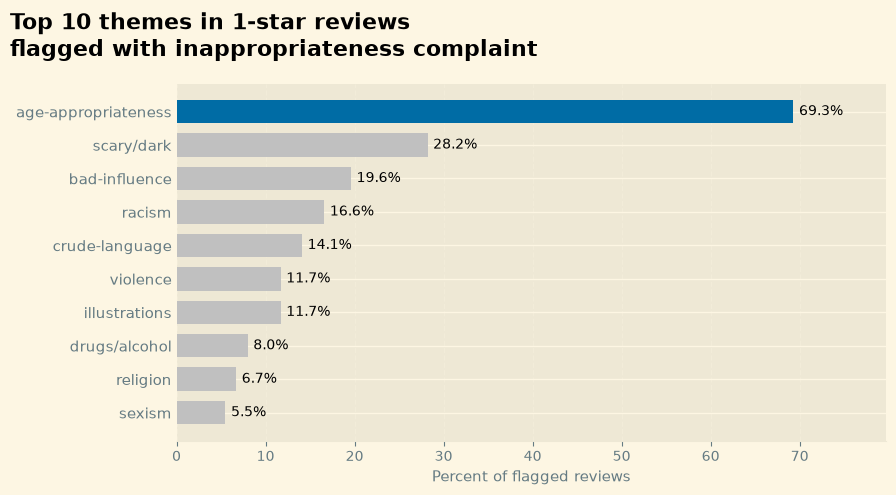

In [15]:

data = pct_of_reviews.sort_values() # sorting values from smallest to largest

colors = ["#006CA5" if name == "age-appropriateness" else "#C0C0C0" for name in data.index] # coloring in largest bar

fig, ax = plt.subplots(figsize=(9, 5)) # sizing the figure
bars = ax.barh(data.index, data.values, color=colors, height=0.7) # creating horizontal bars for each theme


ax.bar_label(bars, fmt="%.1f%%", padding=4, fontsize=10) # percent value labels at the end of every bar

# adding title and x/y labels
fig.suptitle("Top 10 themes in 1-star reviews\nflagged with inappropriateness complaint",
             x=0.01, ha="left", fontsize=16, fontweight="bold")
ax.set_xlabel("Percent of flagged reviews", fontsize=11)
ax.set_ylabel("")

# cleaning up aesthetics
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.tick_params(axis="y", length=0, labelsize=11)
ax.xaxis.grid(True, linestyle="--", alpha=0.3)
ax.set_axisbelow(True)
ax.set_xlim(0, data.max() * 1.15)  # room for the value labels

plt.tight_layout() # making sure labels don't overlap
plt.show()

### Visualizing themes for age-appropriateness labeled reviews.

#### Themes shown as a percentage of total age-appropriateness labeled reviews. Because some reviews may be flagged with multiple labels, the percentage totals don't equal 100.

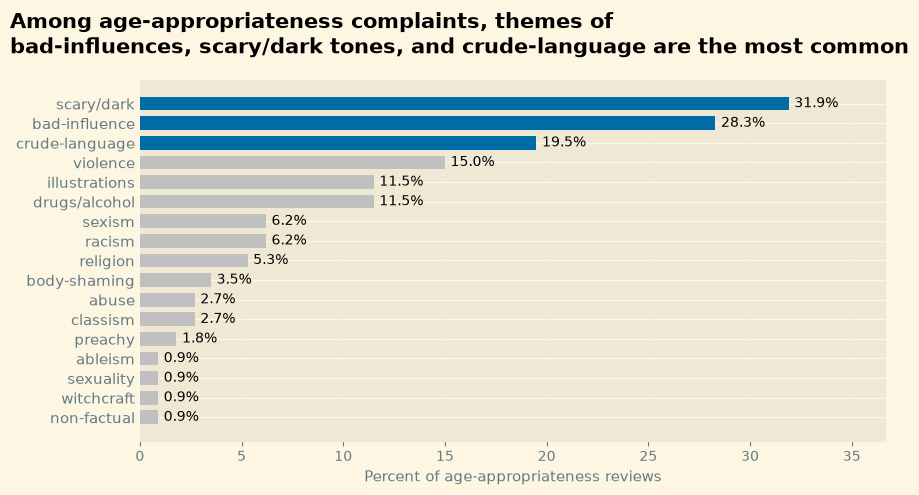

In [16]:
data = pct_others_and_age.sort_values() # sorting values from smallest to largest

highlight = ["bad-influence", "scary/dark", "crude-language"] # highlighting top three themes
colors = ["#006CA5" if label in highlight else "#C0C0C0" for label in data.index]

fig, ax = plt.subplots(figsize=(9, 5)) # sizing the figure
bars = ax.barh(data.index, data.values, color=colors, height=0.7) # creating horizontal bars for each theme

ax.bar_label(bars, fmt="%.1f%%", padding=4, fontsize=10) # percent value labels at the end of every bar

# adding title and x/y axis labels
fig.suptitle("Among age-appropriateness complaints, themes of\nbad-influences, scary/dark tones, and crude-language are the most common",
             x=0.01, ha="left", fontsize=15, fontweight="bold")
ax.set_xlabel("Percent of age-appropriateness reviews", fontsize=11)
ax.set_ylabel("")

# cleaning up aesthetics
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.tick_params(axis="y", length=0, labelsize=11)
ax.xaxis.grid(True, linestyle="--", alpha=0.3)
ax.set_axisbelow(True)
ax.set_xlim(0, data.max() * 1.15)

plt.tight_layout() # making sure labels don't overlap
plt.show()

##### highlighted in green are the themes/labels that are always paired with age-appropriateness 

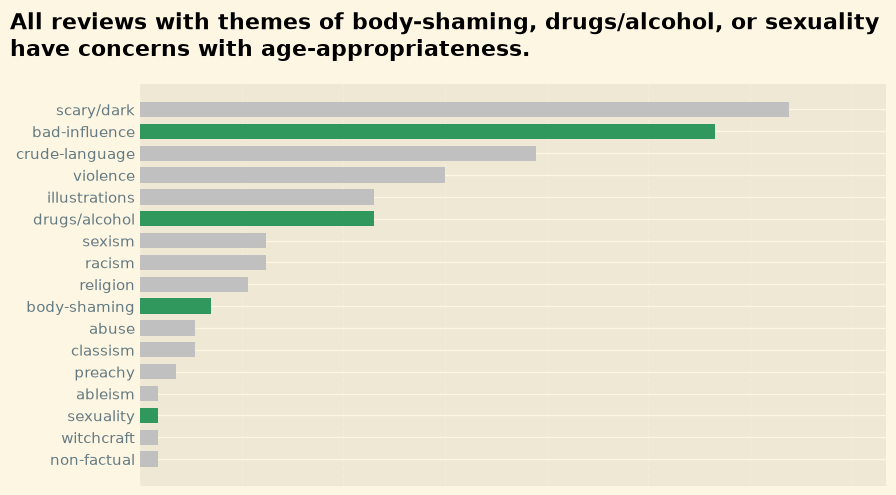

In [17]:
data = pct_others_and_age.sort_values()

highlight = ["bad-influence", "body-shaming", "drugs/alcohol", "sexuality"]
colors = ["#30975d" if label in highlight else "#C0C0C0" for label in data.index]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(data.index, data.values, color=colors, height=0.7)

fig.suptitle("All reviews with themes of body-shaming, drugs/alcohol, or sexuality\nhave concerns with age-appropriateness.",
             x=0.01, ha="left", fontsize=16, fontweight="bold")
ax.set_xlabel("", fontsize=11)
ax.set_ylabel("")

for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.tick_params(axis="y", length=0, labelsize=11)
ax.tick_params(axis="x", bottom=False, labelbottom=False)
ax.xaxis.grid(True, linestyle="--", alpha=0.3)
ax.set_axisbelow(True)
ax.set_xlim(0, data.max() * 1.15)

plt.tight_layout()
plt.show()

### Visualizing what themes are most common among age-appropriateness complaints

In [20]:
others

llm_labels
scary/dark        36
bad-influence     32
crude-language    22
violence          17
illustrations     13
drugs/alcohol     13
racism             7
sexism             7
religion           6
body-shaming       4
abuse              3
classism           3
preachy            2
sexuality          1
witchcraft         1
ableism            1
non-factual        1
Name: count, dtype: int64

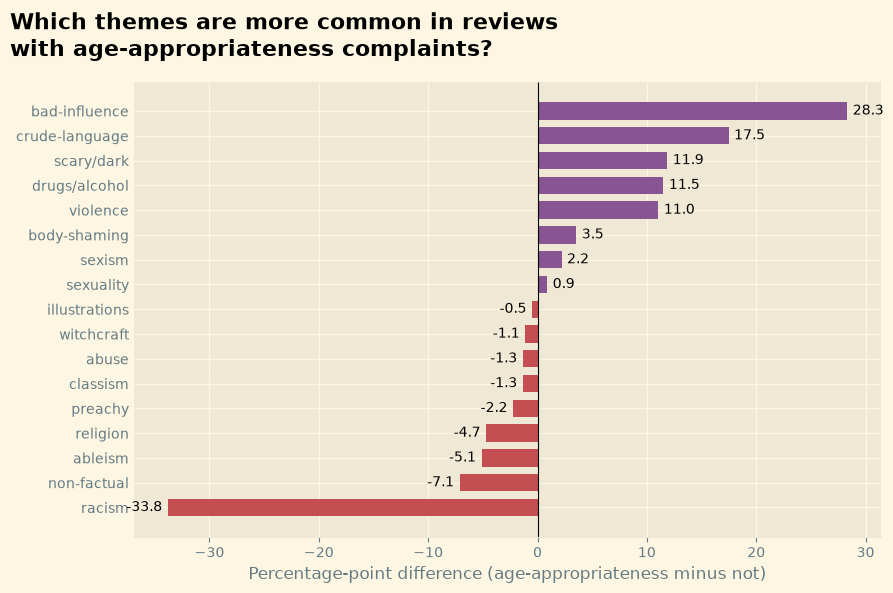

In [22]:
target = "age-appropriateness" # creating an object of the label we're looking at

others_viz = df_analysis.explode("llm_labels") # creating an object of other labels. using explode the separate multiple labels in a review into their own rows
others_viz = others_viz[others_viz["llm_labels"] != target].dropna(subset=["llm_labels"]) # dropping target so it won't have a bar

counts_in_age = others_viz.groupby(["llm_labels", "has_age"]).size().unstack(fill_value=0) # counting each label and their appearance in "age-appropriateness" reviews
counts_in_age = counts_in_age.rename(columns={True: "Age-appropriateness", False: "Not age-appropriateness"})

# making a series with the numbers of both groups
group_sizes = pd.Series({ 
    "Age-appropriateness": len(df_age_only),
    "Not age-appropriateness": len(df_not_age),
})
pct = counts_in_age / group_sizes * 100

# calculating difference in percentage points
diff = (pct["Age-appropriateness"] - pct["Not age-appropriateness"]).sort_values()

# plotting the data
colors = ["#C44E52" if v < 0 else "#875692" for v in diff]

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(diff.index, diff.values, color=colors, height=0.7)
ax.bar_label(bars, fmt="%.1f", padding=4, fontsize=10)
ax.axvline(0, color="black", linewidth=0.8)

ax.set_xlabel("Percentage-point difference (age-appropriateness minus not)")
ax.set_ylabel("")
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.tick_params(axis="y", length=0)

fig.suptitle("Which themes are more common in reviews\nwith age-appropriateness complaints?",
             x=0.01, ha="left", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

#### Split between 1-star reviews about general inappropriateness concerns and children-specific appropriateness concerns

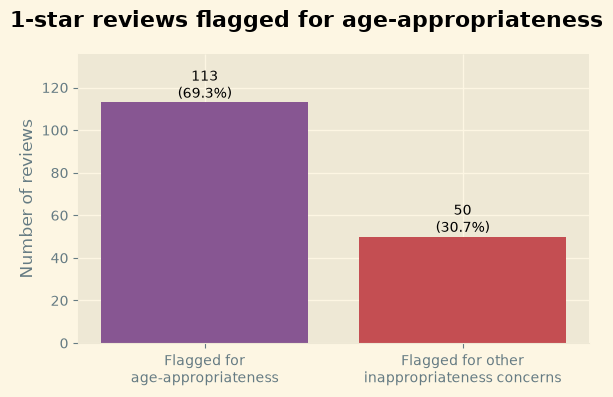

In [23]:
counts_viz2 = df_analysis["has_age"].value_counts().reindex([True, False], fill_value=0)
names = ["Flagged for\nage-appropriateness", "Flagged for other\ninappropriateness concerns"]

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(names, counts_viz2.values, color=["#875692", "#C44E52"])

for bar, n in zip(bars, counts_viz2.values):
    ax.text(bar.get_x() + bar.get_width() / 2, n,
            f"{n}\n({n / num_total:.1%})", ha="center", va="bottom")

ax.set_ylabel("Number of reviews")
ax.set_ylim(0, counts.max() * 1.2)
ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("1-star reviews flagged for age-appropriateness",
             x=0.01, ha="left", fontsize=16, fontweight="bold")

plt.tight_layout()
plt.show()